# 05 — Split Data
**Stratified 70 / 15 / 15** (train / validasi / test), `seed = 42`, **tanpa tumpang tindih**.

Input: `output/fitur.csv` → Output: `output/split.csv` (kolom `split` = train / val / test).

Tidak ada langkah praproses yang "belajar" dari data (semua per-citra), dan `StandardScaler` nanti ada di dalam Pipeline notebook 06 (hanya fit di data latih), jadi tidak ada kebocoran data walau fitur diekstrak sebelum split.

In [1]:
from pathlib import Path
import json, random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Root proyek = folder pcv_bkpm (otomatis, baik dijalankan dari notebooks/ maupun root)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "dataset_crop"      # input: citra daun hasil crop, 1 subfolder = 1 kelas
OUT  = ROOT / "output"            # semua hasil notebook disimpan di sini
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CLASSES = sorted(p.name for p in DATA.iterdir() if p.is_dir())   # label = nama subfolder

def imread(path, flags=cv2.IMREAD_COLOR):          # aman untuk path Windows ber-spasi/non-ASCII
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), flags)

def imwrite(path, img):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, img); buf.tofile(str(path)); return ok

def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("ROOT   :", ROOT)
print("Kelas  :", CLASSES)

ROOT   : D:\SEMESTER 5\pcv_bkpm
Kelas  : ['bercak_daun', 'sehat', 'ulat', 'virus_gemini']


c:\Users\Shobri\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from sklearn.model_selection import train_test_split

df = pd.read_csv(OUT / "fitur.csv")
print("Total sampel:", len(df))
display(df.label_name.value_counts().rename("jumlah").to_frame())
assert df.path.is_unique, "Ada path ganda di fitur.csv"

Total sampel: 240


,jumlah
label_name,
virus_gemini,90
bercak_daun,50
sehat,50
ulat,50


## 1. Split bertingkat (stratified)

In [3]:
idx = np.arange(len(df)); y = df.label_id.to_numpy()

# 70% train, 30% sisa -> dibagi dua sama besar jadi 15% val + 15% test
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)

df["split"] = ""
df.loc[idx_train, "split"] = "train"
df.loc[idx_val, "split"] = "val"
df.loc[idx_test, "split"] = "test"

print({k: len(v) for k, v in {"train": idx_train, "val": idx_val, "test": idx_test}.items()})
print("Proporsi:", (df.split.value_counts(normalize=True).reindex(["train", "val", "test"]) * 100).round(1).to_dict())

{'train': 168, 'val': 36, 'test': 36}
Proporsi: {'train': 70.0, 'val': 15.0, 'test': 15.0}


## 2. Verifikasi: tanpa tumpang tindih & proporsi kelas terjaga

In [4]:
s_tr, s_va, s_te = (set(df[df.split == k].path) for k in ["train", "val", "test"])
print("train ∩ val  =", len(s_tr & s_va))
print("train ∩ test =", len(s_tr & s_te))
print("val ∩ test   =", len(s_va & s_te))
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te)
assert len(s_tr) + len(s_va) + len(s_te) == len(df)
print("OK: tidak ada tumpang tindih, semua sampel terpakai tepat sekali.")

tab = pd.crosstab(df.label_name, df.split)[["train", "val", "test"]]
tab["total"] = tab.sum(axis=1)
display(tab)
display((pd.crosstab(df.label_name, df.split, normalize="index")[["train", "val", "test"]] * 100).round(1))

train ∩ val  = 0
train ∩ test = 0
val ∩ test   = 0
OK: tidak ada tumpang tindih, semua sampel terpakai tepat sekali.


split,train,val,test,total
label_name,,,,
bercak_daun,35,7,8,50
sehat,35,8,7,50
ulat,35,7,8,50
virus_gemini,63,14,13,90


split,train,val,test
label_name,,,
bercak_daun,70.0,14.0,16.0
sehat,70.0,16.0,14.0
ulat,70.0,14.0,16.0
virus_gemini,70.0,15.6,14.4


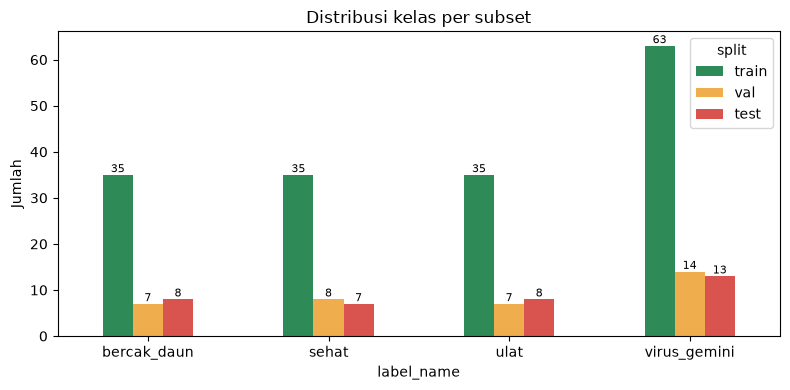

In [5]:
ax = tab[["train", "val", "test"]].plot.bar(figsize=(8, 4), color=["#2e8b57", "#f0ad4e", "#d9534f"])
for c in ax.containers: ax.bar_label(c, fontsize=8)
plt.title("Distribusi kelas per subset"); plt.xticks(rotation=0); plt.ylabel("Jumlah"); plt.tight_layout(); plt.show()

In [6]:
df.to_csv(OUT / "split.csv", index=False)
print("Tersimpan:", OUT / "split.csv")
display(df[["path", "label_name", "label_id", "split"]].sample(6, random_state=SEED))

Tersimpan: D:\SEMESTER 5\pcv_bkpm\output\split.csv


,path,label_name,label_id,split
24,output/03_rekonstruksi/bercak_daun/IMG_2026110...,bercak_daun,0,train
6,output/03_rekonstruksi/bercak_daun/IMG_2026110...,bercak_daun,0,train
93,output/03_rekonstruksi/sehat/WhatsApp Image 20...,sehat,1,val
109,output/03_rekonstruksi/ulat/IMG_20261108_16043...,ulat,2,train
104,output/03_rekonstruksi/ulat/images (3).png,ulat,2,test
172,output/03_rekonstruksi/virus_gemini/IMG_202611...,virus_gemini,3,train
